In [3]:
# 1. Install necessary libraries
!pip install roboflow ultralytics opencv-python-headless matplotlib -q

# 2. Download dataset from Roboflow
from roboflow import Roboflow

rf = Roboflow(api_key="zJFaqjr3gA7ZzLDF3iMP")
project = rf.workspace("testcasque").project("ppe-detection-qlq3d")
version = project.version(1)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to PPE-detection-1 in yolov8:: 100%|██████████| 10292/10292 [00:01<00:00, 7378.18it/s]


In [4]:
from ultralytics import YOLO

# Load pre-trained base model
model = YOLO('yolov8n.pt')

# Train on the downloaded dataset
results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=30,
    imgsz=640,
    batch=16,
    project='rallis_safety',
    name='helmet_detector'
)

Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/PPE-detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet_detector, nbs


image 1/1 /kaggle/working/PPE-detection-1/test/images/Photin0314_jpg.rf.be33aa017a4adcd560cee0ece9dcdeab.jpg: 640x640 1 vest, 7.2ms
Speed: 1.6ms preprocess, 7.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


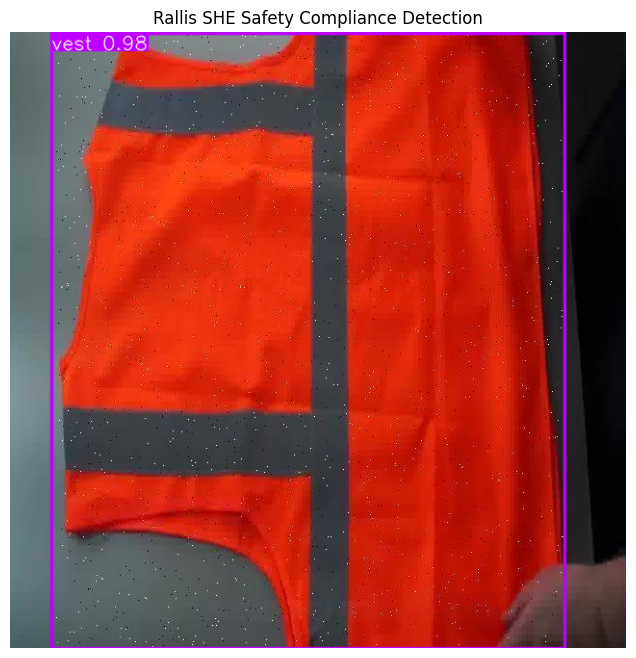

In [6]:
import cv2
import glob
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Corrected path based on your output
best_model = YOLO('/kaggle/working/runs/detect/rallis_safety/helmet_detector/weights/best.pt')

# Pick a test image from the dataset
test_imgs = glob.glob(f"{dataset.location}/test/images/*.jpg")
sample_img = test_imgs[0] if test_imgs else f"{dataset.location}/train/images/*.jpg"

# Run inference
results = best_model(sample_img)

# Render and plot output inline
res_bgr = results[0].plot()
res_rgb = cv2.cvtColor(res_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(res_rgb)
plt.axis('off')
plt.title("Rallis SHE Safety Compliance Detection")
plt.show()